# Series Temporals

Un dels problemes clàsics del machine learning és predir el futur en base a les tendències del passat. 

Els algorismes de series temporals no són distints als de regressió o classificació clàsics o al deep learning que ja hem vist. El que canvia és la manera de preparar els datasets i entrenar. Molts algorismes de Machine Learning (com Random Forest, XGBoost) o de Deep Learning (com xarxes neuronals tridimensionals o lineals) no entenen el concepte "temporal" per si sols. Per ensenyar-los a predir el futur, transformem la sèrie temporal en un dataset de regressió tradicional mitjançant la tècnica de finestres lliscants (sliding windows) o retards (lags).

Una serie temporal prediu un valor futur en base a `N` observacions del passat fins al moment. Per tant, les variables són la mateixa variable observada `N` vegades fins al moment.  

L'ordre temporal importa (No-iid): En regressió clàssica, les files del dataset són independents i idènticament distribuïdes (iid), per la qual cosa pots fer un train_test_split barrejant les dades aleatòriament. En sèries temporals mai pots barrejar el futur amb el passat per entrenar, ja que cauries en data leakage (fuga de dades). Cal dividir les dades de manera estrictament cronològica.

**Variables exògenes** (Sèries multivariades): Tot i que sovint prediguem una variable en funció del seu propi passat, moltes vegades afegim variables externes o exògenes (per exemple, predir la demanda d'energia basant-nos no només en el consum passat, sinó també en la temperatura prevista o els dies festius).

Encara que l'enfocament de regressió amb lags funciona molt bé, existeixen famílies de models estadístics tradicionals (com ARIMA o Exponential Smoothing) i models específics de Deep Learning (com LSTMs, GRUs o Transformers de sèries temporals) dissenyats nativament per capturar dependències temporals sense necessitat de calcular manualment tots els lags.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import datetime
import matplotlib.ticker as ticker


In [2]:
import numpy as np

with open("datos_temperatura.csv", "r") as datafile:

    ts_list_train = []

    for line in datafile:
        row = np.array(
            [float(x) for x in line.strip().split(",") if x != ""],
            dtype=np.float32
        )

        ts_list_train.append(row)

In [3]:
print("Files in ts_list_train:", len(ts_list_train))
print("Length of the first time series:", len(ts_list_train[0]))

Files in ts_list_train: 12
Length of the first time series: 44436


## Estructura i Transformació de Dades per a Xarxes Neuronals en Sèries Temporals

En projectes de Machine Learning i Deep Learning aplicats a sèries temporals multi-entitat (com dades meteorològiques de múltiples ciutats), l'elecció de l'estructura de dades i la seva transformació a tensors de dimensions específiques és crítica per garantir l'eficiència computacional.

Per a un conjunt de dades compost per **12 ciutats** i un registre històric aproximat de **44.436 valors temporals** per cadascuna d'elles, l'organització òptima de les dades crues s'estructura generalment en una matriu o **format ample (*wide format*)**:

* **Files:** Entitats úniques (ciutats).
* **Columnes:** Eix temporal seqüencial.

Aquest enfocament evita la sobrecàrrega de memòria RAM que suposaria gestionar un format llarg (*long* o *tidy*) amb centenars de milers de files repetitives, facilitant el càlcul vectoritzat per a la normalització i la extracció de seqüències.

Per tal d'entrenar models de Deep Learning (com xarxes neuronals recurrents LSTM, GRU o arquitectures convolucionals 1D), les dades s'han de processar mitjançant la tècnica de **finestres lliscants (*sliding windows*)**. Aquest procés transforma la matriu bidimensional original en un tensor tridimensional.

En l'àmbit de l'anàlisi de dades, les sèries temporals multi-entitat es poden estructurar principalment en dos formats: el **format ample (*wide*)**, on cada fila representa una entitat única (com una ciutat) i les columnes actuen com a eix temporal, sent ideal per a comparacions visuals directes i càlculs matricials; i el **format llarg (*long* o *tidy*)**, on cada fila correspon a una observació individual i datada per a cada entitat, sent aquest últim l'estàndard recomanat per a pipelines de Machine Learning i llibreries analítiques gràcies a la seva flexibilitat per gestionar múltiples variables i operacions d'agrupació.

## Dibuixar la serie temporal


In [6]:
headers = ['San Francisco', 'Los Angeles', 'Las Vegas', 'Dallas', 'Houston',
           'Chicago', 'Detroit', 'Miami', 'Toronto', 'Philadelphia',
           'New York', 'Boston']

# Fecha inicial:  1 de octubre de 2012 a las 13:00 horas.
initial_moment = datetime.datetime(2012, 10, 1, 13, 0)

colors = plt.get_cmap('Set1', len(headers)) # treure tants colors com ciutats hi ha del cmap Set1

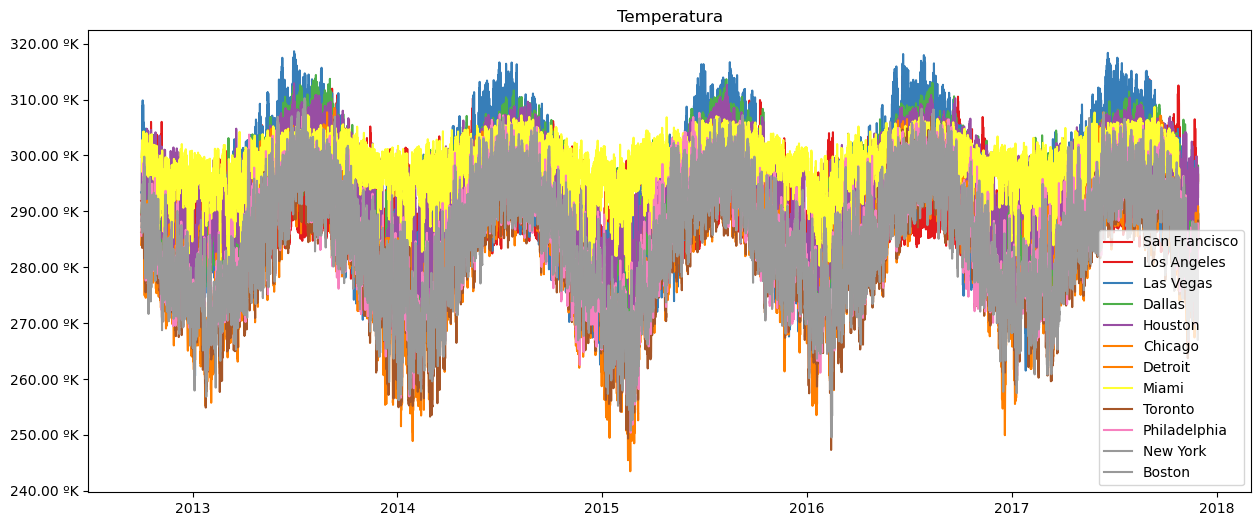

In [9]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,6))
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%1.2f ºK'))

for i in range(len(headers)):
  # Generem una llista de dates a partir de la data inicial, afegint una hora per cada valor de la sèrie temporal
  x = [initial_moment + datetime.timedelta(hours=j, minutes=0) for j in range(ts_list_train[i].shape[0])]
  ax.plot(x, ts_list_train[i], label=headers[i], c=colors(i))
ax.legend()
ax.set_title("Temperatura")
plt.show()

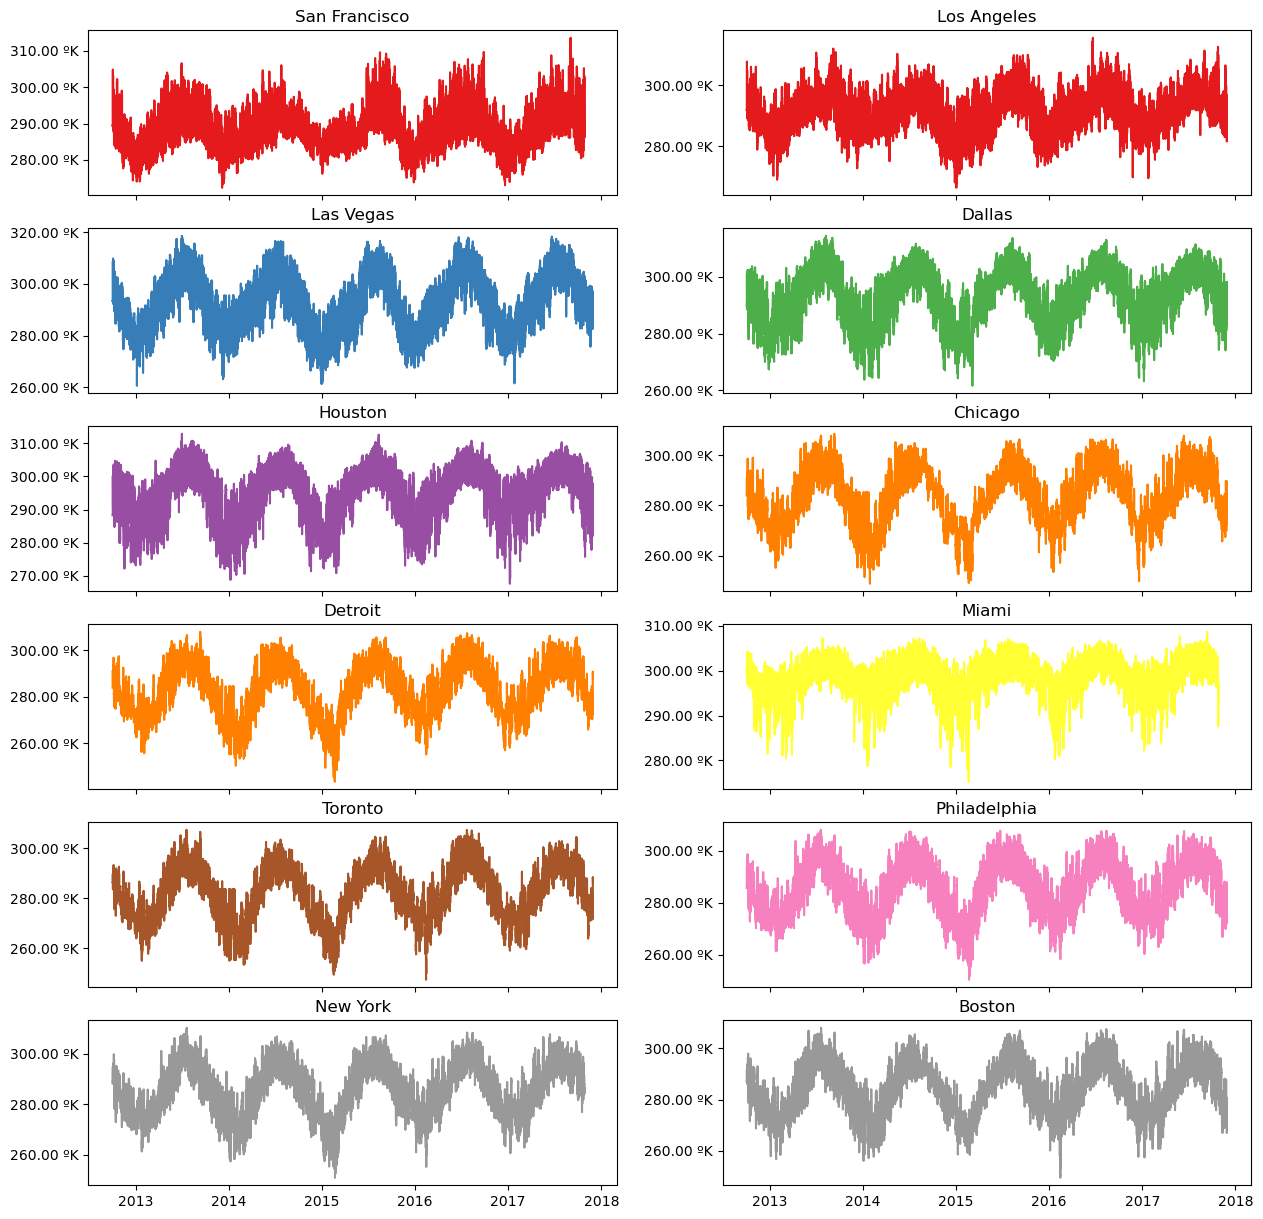

In [12]:


fig, ax = plt.subplots(nrows=np.ceil(len(headers)/2).astype(int), ncols=2, figsize=(15,15), sharex=True)

for i in range(len(headers)):

  x = [initial_moment + datetime.timedelta(hours=j, minutes=0)for j in range(ts_list_train[i].shape[0])]
  ax[i//2][i%2].yaxis.set_major_formatter(ticker.FormatStrFormatter('%1.2f ºK'))
  ax[i//2][i%2].set_title(headers[i])
  ax[i//2][i%2].plot(x, ts_list_train[i], label=headers[i], c=colors(i))

plt.show()

Com que hi ha ciutats amb temperatures més extremes cal normalitzar les dades. No utilitzem `StandardScaler` perquè l'estructura de les dades no està per columnes i perquè volem normalitzar fila a fila. Amés, normalitzem com fa MinMax perquè les xarxes neuronals poden exigir valors entre 0 i 1. Per fer-ho més ràpid transformarem a `Numpy` i ho farem vectorialment. 

Com que tenim més de 44000 registres per a cada ciutat no passa res per eliminar alguns de les ciutats que més tenen per convertir en una matriu Numpy: 

In [18]:
min_longitud = min(len(x) for x in ts_list_train)
llista_igualada = [x[:min_longitud] for x in ts_list_train]

matriu = np.array(llista_igualada)

print(matriu.shape)

# Calculem el mínim i màxim de cada fila (ciutat) per separat
min_vals = matriu.min(axis=1, keepdims=True)
max_vals = matriu.max(axis=1, keepdims=True)

print("Mínims:", min_vals)
print("Màxims:", max_vals)

# Apliquem la fórmula (gràcies a 'keepdims=True', NumPy s'encarrega del broadcasting automàticament)
matriu_norm = (matriu - min_vals) / (max_vals - min_vals)


(12, 44424)
Mínims: [[272.3    ]
 [266.50366]
 [260.56134]
 [261.61032]
 [267.57   ]
 [248.89   ]
 [243.48334]
 [275.23334]
 [247.3    ]
 [250.39   ]
 [250.774  ]
 [249.54   ]]
Màxims: [[313.62]
 [315.47]
 [318.64]
 [314.4 ]
 [312.91]
 [308.48]
 [308.05]
 [308.68]
 [307.28]
 [308.  ]
 [310.24]
 [308.  ]]


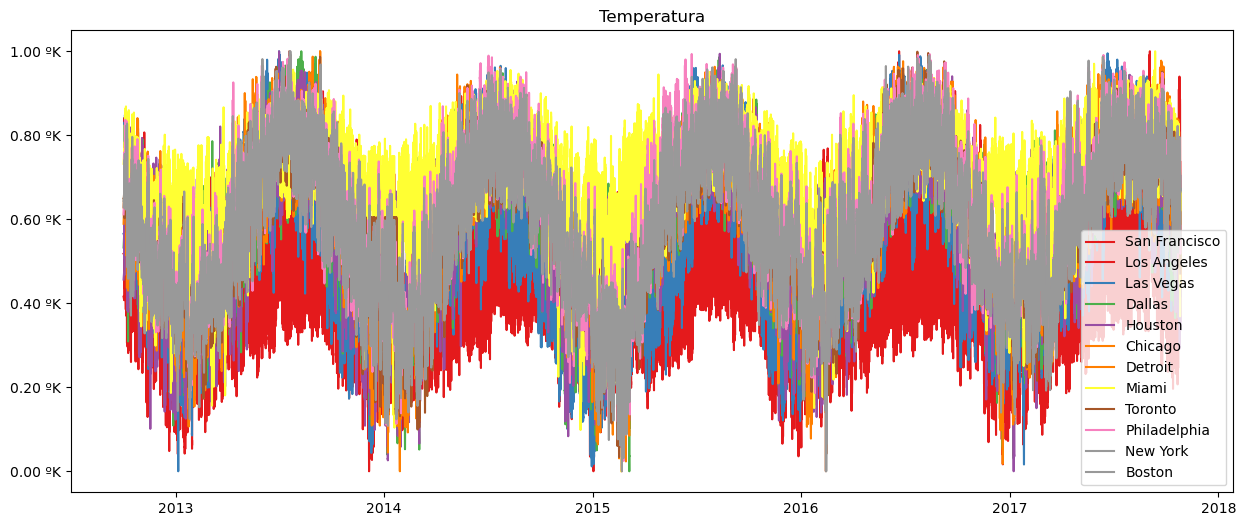

In [19]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,6))
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%1.2f ºK'))

for i in range(len(headers)):
  # Generem una llista de dates a partir de la data inicial, afegint una hora per cada valor de la sèrie temporal
  x = [initial_moment + datetime.timedelta(hours=j, minutes=0) for j in range(matriu_norm[i].shape[0])]
  ax.plot(x, matriu_norm[i], label=headers[i], c=colors(i))
ax.legend()
ax.set_title("Temperatura")
plt.show()

Les xarxes neuronals aprenen patrons temporals amb les `finestres de predicció`. Cal transformar el dataset en una altra estructura utilitzant una quantitat d'observacions del passat per predir una altra quantitat d'observacions del futur. 

Es considera que per a predir una dada del futur es necessiten unes 15 del passat. Si volem predir les 24 hores següents necessitarem al menys 24x15 = 360 observacions del passat. 


In [21]:
import numpy as np

def create_sliding_windows(matrix, input_width=360, label_width=24):
    """
    Transforma una matriu de (num_ciutats, num_temps) en tensors de finestres lliscants.
    
    Paràmetres:
    - matrix: np.array de forma (12, 44424)
    - input_width: nombre de passos passats (historial) -> 360
    - label_width: nombre de passos futurs a predir -> 24
    """
    X_list = []
    y_list = []
    
    num_cities, num_timesteps = matrix.shape
    total_window_size = input_width + label_width
    
    # Recorrem ciutat per ciutat
    for i in range(num_cities):
        city_data = matrix[i]
        
        # Fem lliscar la finestra al llarg del temps d'aquesta ciutat
        for start_idx in range(num_timesteps - total_window_size + 1):
            end_input_idx = start_idx + input_width
            end_label_idx = end_input_idx + label_width
            
            # Extrec la finestra del passat (entrada)
            X_window = city_data[start_idx:end_input_idx]
            # Extrec la finestra del futur (objectiu / target)
            y_window = city_data[end_input_idx:end_label_idx]
            
            X_list.append(X_window)
            y_list.append(y_window)
            
    # Convertim les llistes a arrays de NumPy
    X = np.array(X_list)
    y = np.array(y_list)
    
    
    # Afegim la dimensió de features al final (passant de (N, 360) a (N, 360, 1)) util per a models LSTM/GRU que esperen una entrada 3D
    X = np.expand_dims(X, axis=-1)
    
    return X, y


X, y = create_sliding_windows(matriu_norm, input_width=360, label_width=24)

print("Forma de X (Entrada al model):", X.shape)  # Hauria de ser (~528492, 360, 1)
print("Forma de y (Objectiu a predir):", y.shape)  # Hauria de ser (~528492, 24)

Forma de X (Entrada al model): (528492, 360, 1)
Forma de y (Objectiu a predir): (528492, 24)


## Solució amb XGBoost

Models basats en arbres com XGBoost (o LightGBM) s'utilitzen en sèries temporals i, moltes vegades, poden competir de tu a tu (o fins i tot superar) a les xarxes LSTM, amb l'avantatge enorme que s'entrenen en una fracció del temps.

XGBoost té suport natiu per a regressió multi-output (Multi-target regression). Això significa que pots passar-li una matriu d'objectius y de forma (Batch, 24), i XGBoost s'encarregarà d'entrenar els arbres de decisió per predir les 24 sortides simultàniament en una sola passada.

## Solució amb Xarxes neuronals Pytorch i LSTM

Creem la xarxa neuronal LSTM, observem que els seus paràmetres són que `input_size = 1`. Cal tenir en compte que és 1 perquè LSTM no rep els 360 valors d'una vegada, sino que van entrant un a un i va "memoritzant-los". Al final treu una eixida de 64 neurones com a resum del que ha resumir i interpretat la capa LSTM. Aquesta eixida va a una capa lineal `Full connected` amb una eixida de 24 prediccions a mode de regressió multioutput. 

In [ ]:
import torch
import torch.nn as nn

class LSTMTemperaturePredictor(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=24, num_layers=1):
        super(LSTMTemperaturePredictor, self).__init__()
        
        # Capa LSTM
        # batch_first=True fa que l'entrada sigui: (batch_size, seq_len, features)
        self.lstm = nn.LSTM(
            input_size=input_size, 
            hidden_size=hidden_size, 
            num_layers=num_layers, 
            batch_first=True
        )
        
        # Capa Densa (Lineal) per a l'eixida
        # Transforma l'estat ocult de l'LSTM (hidden_size) als 24 passos futurs
        self.fc = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        # x forma d'entrada: (batch_size, 360, 1)
        
        # Passem les dades per l'LSTM
        # out: (batch_size, seq_len, hidden_size) -> conté la sortida de tots els passos
        # (hn, cn): estat ocult i de cèl·lula final
        out, (hn, cn) = self.lstm(x)
        
        # Ens interessa l'últim estat ocult de l'última capa de l'LSTM (hn[-1])
        # Això resumeix tota la informació de la finestra de 360 passos.
        # Forma de hn[-1]: (batch_size, hidden_size)
        last_hidden_state = hn[-1]
        
        # Passem l'estat per la capa densa
        # Forma final: (batch_size, 24)
        predictions = self.fc(last_hidden_state)
        
        return predictions

# --- INSTANCIAR EL MODEL ---
model = LSTMTemperaturePredictor(input_size=1, hidden_size=64, output_size=24)
print(model)

Ara cal transformar el dataset en tensors, configurar el Dataloader, dividir en train i test, definir la funció de pèrdua i el bucle d'entrenament. 